# ED408 — Statistical Machine Learning II Lab
## Experiment 9: Genetic Algorithm for the Travelling Salesman Problem

We have $N=25$ random cities. A tour is a **permutation** of the cities and its cost is the closed-loop length
$$L(\pi)=\sum_{i=1}^{N} d(\pi_i,\pi_{i+1}),\qquad \pi_{N+1}=\pi_1 .$$
Binary encoding doesn't work here, since ordinary crossover would produce tours that repeat cities. So the GA uses permutation-safe operators:

| Step | Operator |
|---|---|
| Fitness | $1/L(\pi)$ (we just minimise $L$) |
| Selection | tournament of size $k=3$ |
| Crossover | **Order Crossover (OX)**: copy a slice from parent 1, fill the rest in parent 2's order |
| Mutation | **inversion**: reverse a random sub-tour (a 2-opt move) |
| Elitism | best 2 tours copied unchanged to the next generation |


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

rng = np.random.default_rng(7)
N = 25
cities = rng.uniform(0, 100, (N, 2))
D = np.linalg.norm(cities[:, None] - cities[None], axis=-1)   # distance matrix

def tour_length(t):
    return D[t, np.roll(t, -1)].sum()

def plot_tour(t, ax, title):
    loop = np.append(t, t[0])
    ax.plot(*cities[loop].T, "-o", ms=4)
    ax.scatter(*cities[t[0]], c="r", s=60, zorder=3)
    ax.set_title(f"{title}  (L = {tour_length(t):.1f})"); ax.set_aspect("equal")

In [2]:
def tournament(pop, lengths, k=3):
    idx = rng.choice(len(pop), k, replace=False)
    return pop[idx[np.argmin(lengths[idx])]]

def order_crossover(p1, p2):
    n = len(p1)
    a, b = sorted(rng.choice(n, 2, replace=False))
    child = -np.ones(n, dtype=int)
    child[a:b+1] = p1[a:b+1]
    taken = set(p1[a:b+1])
    rest = [c for c in np.roll(p2, -(b+1)) if c not in taken]   # p2 order, starting after the slice
    child[[(b + 1 + i) % n for i in range(len(rest))]] = rest
    return child

def inversion_mutation(t, pm):
    t = t.copy()
    if rng.random() < pm:
        a, b = sorted(rng.choice(len(t), 2, replace=False))
        t[a:b+1] = t[a:b+1][::-1]
    return t

def genetic_algorithm(pop_size=150, generations=500, pc=0.9, pm=0.3, elite=2):
    pop = np.array([rng.permutation(N) for _ in range(pop_size)])
    best_hist, mean_hist = [], []
    for g in range(generations):
        lengths = np.array([tour_length(t) for t in pop])
        order = np.argsort(lengths)
        best_hist.append(lengths[order[0]]); mean_hist.append(lengths.mean())
        new = [pop[i] for i in order[:elite]]                 # elitism
        while len(new) < pop_size:
            p1, p2 = tournament(pop, lengths), tournament(pop, lengths)
            child = order_crossover(p1, p2) if rng.random() < pc else p1.copy()
            new.append(inversion_mutation(child, pm))
        pop = np.array(new)
    lengths = np.array([tour_length(t) for t in pop])
    return pop[np.argmin(lengths)], best_hist, mean_hist

# sanity check: OX always returns a valid permutation
p1, p2 = rng.permutation(10), rng.permutation(10)
c = order_crossover(p1, p2)
print("p1   :", p1, "\np2   :", p2, "\nchild:", c, " valid:", sorted(c) == list(range(10)))

p1   : [1 4 3 8 2 7 9 0 6 5] 
p2   : [8 0 3 4 7 5 9 6 1 2] 
child: [8 3 4 1 2 7 9 0 6 5]  valid: True


In [3]:
random_tour = rng.permutation(N)
best_tour, best_hist, mean_hist = genetic_algorithm()

# nearest-neighbour heuristic as a reference
def nearest_neighbour(start=0):
    tour, left = [start], set(range(N)) - {start}
    while left:
        nxt = min(left, key=lambda j: D[tour[-1], j])
        tour.append(nxt); left.remove(nxt)
    return np.array(tour)
nn_best = min((nearest_neighbour(s) for s in range(N)), key=tour_length)

print(f"Random tour            : {tour_length(random_tour):.2f}")
print(f"Nearest-neighbour (best start): {tour_length(nn_best):.2f}")
print(f"Genetic Algorithm      : {tour_length(best_tour):.2f}")
print("GA best tour:", best_tour)

Random tour            : 1299.44
Nearest-neighbour (best start): 510.88
Genetic Algorithm      : 466.91
GA best tour: [23  6  5 16 10 18 11 19  1 17 15  7 14  4  8 22  0  9 21 24 13  2 20  3
 12]


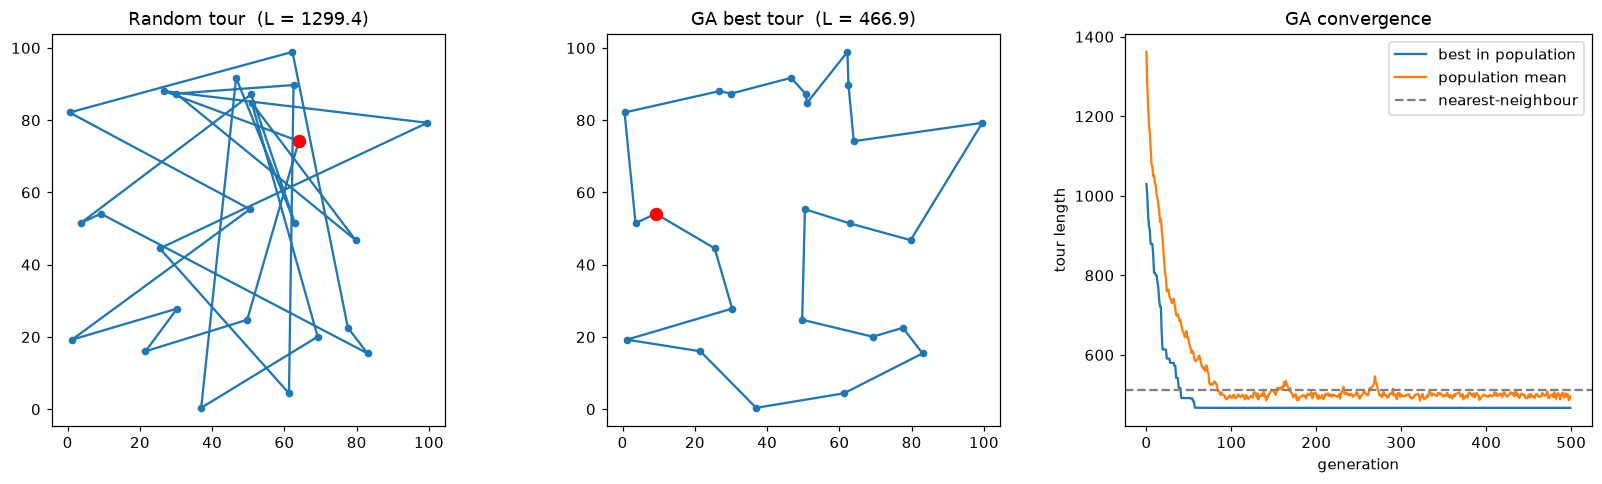

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
plot_tour(random_tour, ax[0], "Random tour")
plot_tour(best_tour, ax[1], "GA best tour")
ax[2].plot(best_hist, label="best in population")
ax[2].plot(mean_hist, label="population mean")
ax[2].axhline(tour_length(nn_best), c="gray", ls="--", label="nearest-neighbour")
ax[2].set(xlabel="generation", ylabel="tour length", title="GA convergence"); ax[2].legend()
plt.tight_layout(); plt.show()

**Observations.**
* The GA shortens the tour from 1299.4 (random) to **466.9**. That beats the best nearest-neighbour tour (510.9, built from every possible start city) by about 9%, and the final tour has no crossing edges, which is a necessary condition for an optimal Euclidean tour.
* Almost all of the improvement comes in the first ~60 generations. After that the best tour stays flat and the population mean hovers just above it, so the population has converged. Order crossover passes on relative city order from the parents, and inversion mutation acts as a random 2-opt move that removes crossings.
* Elitism makes the best-in-population curve monotone. Without it a good tour can be lost to an unlucky crossover.
* A GA gives no optimality guarantee. For 25 cities the search space has $24!/2\approx3\times10^{23}$ tours, so the GA's value is in reaching a very good tour after only $500\times150=75{,}000$ evaluations.